# MassDOT IMPACT Crash Data Initial Look (2023–2025)

**Purpose:** a first look at the crash data our project uses as the **outcome label**
(did a road segment have at least one non-intersection crash in 2023–2025?).

This notebook answers three questions for the team:
1. **Where is the data and how do we download it?** (ArcGIS REST API, as planned in the proposal)
2. **What fields are available**, and which ones does the proposal need?
3. **What does the data look like?** Record counts, crash status, junction types, geocoding quality.

**Source:** MassDOT IMPACT crash open data, one ArcGIS *FeatureServer* per year.
We use **layer 0 (Crash)**, which has one row per crash. Layers 1 (Vehicle) and 2 (Person)
repeat each crash once per vehicle/person, so they would create duplicates.

In [2]:
%pip install requests pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 11.3 MB/s eta 0:00:00MB/s eta 0:00:01:01

[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import time
import requests
import pandas as pd
from pathlib import Path

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)

BASE = "https://gis.crashdata.dot.mass.gov/arcgis/rest/services/MassDOT"

# One service per year. Note: 2023 is named "2023v", not "2023".
SERVICES = {
    2023: "MASSDOT_ODP_OPEN_2023v",
    2024: "MASSDOT_ODP_OPEN_2024",
    2025: "MASSDOT_ODP_OPEN_2025",
}
LAYER = 0  # Crash layer

def layer_url(year):
    return f"{BASE}/{SERVICES[year]}/FeatureServer/{LAYER}"

def get_json(url, params=None, tries=3):
    """GET a URL and return JSON, retrying a few times if the server hiccups."""
    for attempt in range(tries):
        try:
            r = requests.get(url, params=params, timeout=120)
            r.raise_for_status()
            data = r.json()
            if "error" in data:
                raise RuntimeError(data["error"])
            return data
        except Exception as e:
            if attempt == tries - 1:
                raise
            print(f"  retrying after error: {e}")
            time.sleep(3 * (attempt + 1))

## 1. Layer information and available fields

Each layer has a description page listing every field (column). We read it for each year
and check whether the fields are the same across years. The crash report form changed on
January 1, 2024, so 2023 may differ from 2024–2025.

In [2]:
layer_info = {}
for year in SERVICES:
    info = get_json(layer_url(year), {"f": "json"})
    layer_info[year] = info
    print(f"{year}: layer name = {info.get('name')!r}, "
          f"fields = {len(info['fields'])}, "
          f"max records per request = {info.get('maxRecordCount')}, "
          f"ID field = {info.get('objectIdField')}")

2023: layer name = 'Crash', fields = 118, max records per request = 2000, ID field = OBJECTID
2024: layer name = 'Crash', fields = 124, max records per request = 2000, ID field = OBJECTID
2025: layer name = 'Crash', fields = 124, max records per request = 2000, ID field = OBJECTID


In [3]:
# Full field list for the most recent year (name, readable alias, type)
fields_2025 = pd.DataFrame(
    [(f["name"], f.get("alias"), f["type"].replace("esriFieldType", ""))
     for f in layer_info[2025]["fields"]],
    columns=["field", "alias", "type"],
)
fields_2025

,field,alias,type
0,CRASH_NUMB,Crash Number,Integer
1,CITY_TOWN_NAME,City Town Name,String
2,CRASH_DATE_TEXT,Crash Date,String
3,CRASH_TIME_2,Crash Time,String
4,CRASH_DATETIME,Crash Date/Time,Date
5,CRASH_HOUR,Crash Hour,String
6,CRASH_STATUS,Crash Status,String
7,CRASH_SEVERITY_DESCR,Crash Severity,String
8,MAX_INJR_SVRTY_CL,Max Injury Severity Reported,String
9,NUMB_VEHC,Number of Vehicles,Integer


In [4]:
# Compare field names across years
field_sets = {y: {f["name"] for f in layer_info[y]["fields"]} for y in SERVICES}
all_fields = sorted(set().union(*field_sets.values()))

presence = pd.DataFrame(
    {y: ["yes" if f in field_sets[y] else "-" for f in all_fields] for y in SERVICES},
    index=all_fields,
)
differences = presence[(presence != "yes").any(axis=1)]
print(f"Fields in all three years: {(presence == 'yes').all(axis=1).sum()}")
print(f"Fields missing from at least one year: {len(differences)}")
differences

Fields in all three years: 118
Fields missing from at least one year: 6


,2023,2024,2025
NON_MTRST_ALC_SUSPD_TYPE_CL,-,yes,yes
NON_MTRST_CNTRB_CIRC_CL,-,yes,yes
NON_MTRST_DISTRACTED_BY_CL,-,yes,yes
NON_MTRST_DRUG_SUSPD_TYPE_CL,-,yes,yes
NON_MTRST_EVENT_SEQ_CL,-,yes,yes
NON_MTRST_ORIGIN_DEST_CL,-,yes,yes


### Fields the proposal needs

The proposal's data collection plan asks for **crash identifiers, coordinates, reported road
name, and junction classification**, plus fields for auditing the matching.

In [5]:
KEY_FIELDS = {
    "CRASH_NUMB":            "Crash identifier",
    "CRASH_RPT_IDS":         "Police report IDs (backup identifier)",
    "CRASH_DATETIME":        "Date and time",
    "YEAR":                  "Crash year",
    "CITY_TOWN_NAME":        "Municipality (for geographic train/test split)",
    "X":                     "X coordinate, meters (Mass. State Plane, EPSG 26986)",
    "Y":                     "Y coordinate, meters",
    "LAT":                   "Latitude",
    "LON":                   "Longitude",
    "RDWY":                  "Reported roadway name",
    "NEAR_INT_RDWY":         "Nearest intersecting roadway",
    "DIST_DIRC_FROM_INT":    "Distance/direction from intersection",
    "RDWY_JNCT_TYPE_DESCR":  "Roadway junction type (intersection vs not)",
    "CRASH_STATUS":          "Open/closed status (completeness check)",
    "IS_GEOCODED":           "Whether the crash was placed on the map",
    "GEOCODING_METHOD_NAME": "How the location was determined",
    "CRASH_SEVERITY_DESCR":  "Severity (context)",
}

key_table = pd.DataFrame(
    {"description": list(KEY_FIELDS.values()),
     **{y: ["yes" if f in field_sets[y] else "MISSING" for f in KEY_FIELDS] for y in SERVICES}},
    index=list(KEY_FIELDS),
)
key_table

,description,2023,2024,2025
CRASH_NUMB,Crash identifier,yes,yes,yes
CRASH_RPT_IDS,Police report IDs (backup identifier),yes,yes,yes
CRASH_DATETIME,Date and time,yes,yes,yes
YEAR,Crash year,yes,yes,yes
CITY_TOWN_NAME,Municipality (for geographic train/test split),yes,yes,yes
X,"X coordinate, meters (Mass. State Plane, EPSG ...",yes,yes,yes
Y,"Y coordinate, meters",yes,yes,yes
LAT,Latitude,yes,yes,yes
LON,Longitude,yes,yes,yes
RDWY,Reported roadway name,yes,yes,yes


**Note on the "-linked RD" fields:** many columns (e.g. `STREETNAME`, `AADT`, `F_CLASS`,
`NUM_LANES`) are road attributes that MassDOT already attached to each crash using its own
matching. Our team does its own crash-to-road matching, so we should decide whether to ignore
these or use them only as a cross-check. They should probably **not** be model features.

In [6]:
linked = fields_2025[fields_2025["alias"].str.contains("linked RD", na=False)]
print(f"{len(linked)} '-linked RD' fields in 2025")
linked[["field", "alias"]]

45 '-linked RD' fields in 2025


,field,alias
39,JURISDICTN,Jurisdiction-linked RD
72,AADT,AADT-linked RD
73,AADT_YEAR,AADT Year-linked RD
74,PK_PCT_SUT,Peak % Single Unit Trucks-linked RD
75,AV_PCT_SUT,Average Daily % Single Unit Trucks-linked RD
76,PK_PCT_CT,Peak % Combo Trucks-linked RD
77,AV_PCT_CT,Average Daily % Combo Trucks-linked RD
78,CURB,Curb-linked RD
79,TRUCK_RTE,Truck Route-linked RD
80,LT_SIDEWLK,Left Sidewalk Width-linked RD


## 2. How many crashes per year?

The server can count records without downloading them.

In [7]:
counts = {}
for year in SERVICES:
    res = get_json(f"{layer_url(year)}/query",
                   {"where": "1=1", "returnCountOnly": "true", "f": "json"})
    counts[year] = res["count"]

counts_df = pd.Series(counts, name="crashes").to_frame()
counts_df

,crashes
2023,135326
2024,135445
2025,130931


## 3. Summaries computed on the server

These tables use the API's *statistics* option, so they are quick even though each year has
a lot of crashes. They help with three questions:

- **Crash status:** is 2025 finalized, or are many records still open?
- **Junction type:** how many crashes are intersection crashes (excluded from our label)?
- **Geocoding:** how many crashes have a usable location for matching to roads?

In [8]:
def count_by(year, field):
    """Count crashes in a year grouped by one field, computed by the server."""
    if field not in field_sets[year]:
        return pd.Series(dtype=int, name=year)
    oid = layer_info[year]["objectIdField"]
    params = {
        "where": "1=1",
        "groupByFieldsForStatistics": field,
        "outStatistics": f'[{{"statisticType":"count","onStatisticField":"{oid}","outStatisticFieldName":"n"}}]',
        "f": "json",
    }
    res = get_json(f"{layer_url(year)}/query", params)
    rows = [f["attributes"] for f in res["features"]]
    s = pd.DataFrame(rows).set_index(field)["n"] if rows else pd.Series(dtype=int)
    s.index = s.index.fillna("(blank)")
    return s.rename(year)

def table_by(field):
    t = pd.concat([count_by(y, field) for y in SERVICES], axis=1).fillna(0).astype(int)
    return t.sort_values(t.columns[-1], ascending=False)

In [9]:
status = table_by("CRASH_STATUS")
status

,2023,2024,2025
CRASH_STATUS,,,
Open,0,135095,130595
Open Fatal,0,350,336
Closed,135326,0,0


In [10]:
junction = table_by("RDWY_JNCT_TYPE_DESCR")
junction_pct = (junction / junction.sum() * 100).round(1)
print("Counts:")
display(junction)
print("Percent of each year's crashes:")
display(junction_pct)

Counts:


,2023,2024,2025
RDWY_JNCT_TYPE_DESCR,,,
Not at junction,77070,76834,74108
Four-way intersection,22915,22335,21686
T-intersection,20675,21270,20755
Driveway,2800,2841,2860
Y-intersection,2610,2762,2661
Off-ramp,2741,2742,2435
Traffic circle,2040,1991,2007
On-ramp,2186,2112,1897
Not reported,1064,1359,1420


Percent of each year's crashes:


,2023,2024,2025
RDWY_JNCT_TYPE_DESCR,,,
Not at junction,57.0,56.7,56.6
Four-way intersection,16.9,16.5,16.6
T-intersection,15.3,15.7,15.9
Driveway,2.1,2.1,2.2
Y-intersection,1.9,2.0,2.0
Off-ramp,2.0,2.0,1.9
Traffic circle,1.5,1.5,1.5
On-ramp,1.6,1.6,1.4
Not reported,0.8,1.0,1.1


In [11]:
geocoded = table_by("IS_GEOCODED")
geocoded

,2023,2024,2025
IS_GEOCODED,,,
Yes,130128,130375,127417
No,5109,4966,3465
Multiple,39,44,26
Low Confidence,35,50,16
One,15,10,7


In [12]:
geo_method = table_by("GEOCODING_METHOD_NAME")
geo_method

,2023,2024,2025
GEOCODING_METHOD_NAME,,,
At Address,60578,61975,56499
At Intersection,34979,35791,35869
Operator Designated,15813,15817,19442
Mile Marker,7576,8244,8854
(blank),5198,5070,3514
Exit Number,6332,5179,3107
Off Intersection,3935,2693,3041
Rotary,839,617,569
Landmark,76,59,36


## 4. Download the key fields (paginated)

The API returns at most `maxRecordCount` records per request (2,000 for 2025), so we request
the data in pages: records 0–1999, then 2000–3999, and so on, until a page comes back empty.
This is the "paginated ArcGIS REST API requests" step in the proposal.

To keep files small, we only download the key fields above. Raw files go to `data/raw/`,
following the team's folder plan. Each year takes a few minutes.

In [13]:
RAW_DIR = Path("data/raw")
RAW_DIR.mkdir(parents=True, exist_ok=True)

def download_year(year, fields):
    url = f"{layer_url(year)}/query"
    oid = layer_info[year]["objectIdField"]
    page_size = layer_info[year].get("maxRecordCount") or 1000
    wanted = [f for f in fields if f in field_sets[year]] + [oid]

    rows, offset = [], 0
    while True:
        res = get_json(url, {
            "where": "1=1",
            "outFields": ",".join(wanted),
            "returnGeometry": "false",   # X/Y and LAT/LON are already attribute columns
            "orderByFields": oid,        # stable order so pages don't overlap
            "resultOffset": offset,
            "resultRecordCount": page_size,
            "f": "json",
        })
        batch = [f["attributes"] for f in res.get("features", [])]
        if not batch:
            break
        rows.extend(batch)
        offset += len(batch)
        if offset % (page_size * 10) == 0:
            print(f"  {year}: {offset:,} records so far")
        if not res.get("exceededTransferLimit") and len(batch) < page_size:
            break

    df = pd.DataFrame(rows)
    if "CRASH_DATETIME" in df:   # dates arrive as milliseconds since 1970
        df["CRASH_DATETIME"] = pd.to_datetime(df["CRASH_DATETIME"], unit="ms", errors="coerce")
    df["source_service"] = SERVICES[year]
    return df

crashes = {}
for year in SERVICES:
    print(f"Downloading {year}...")
    df = download_year(year, list(KEY_FIELDS))
    out = RAW_DIR / f"crashes_{year}.csv"
    df.to_csv(out, index=False)
    crashes[year] = df
    print(f"  saved {len(df):,} rows to {out} (server count: {counts[year]:,})")

  2023: 20,000 records so far
  2023: 40,000 records so far
  2023: 60,000 records so far
  2023: 80,000 records so far
  2023: 100,000 records so far
  2023: 120,000 records so far
  saved 135,326 rows to data/raw/crashes_2023.csv (server count: 135,326)
  2024: 20,000 records so far
  2024: 40,000 records so far


KeyboardInterrupt: 

## 5. Quick data-quality checks

- Did we get every record the server says exists?
- Are there duplicate crash numbers? (The proposal says to deduplicate.)
- How many crashes are missing coordinates or a road name?

In [14]:
checks = []
for year, df in crashes.items():
    checks.append({
        "year": year,
        "rows downloaded": len(df),
        "server count": counts[year],
        "duplicate CRASH_NUMB": int(df["CRASH_NUMB"].duplicated().sum()) if "CRASH_NUMB" in df else None,
        "missing X/Y": int(df[["X", "Y"]].isna().any(axis=1).sum()) if {"X", "Y"} <= set(df) else None,
        "missing RDWY": int(df["RDWY"].isna().sum()) if "RDWY" in df else None,
        "earliest date": df["CRASH_DATETIME"].min() if "CRASH_DATETIME" in df else None,
        "latest date": df["CRASH_DATETIME"].max() if "CRASH_DATETIME" in df else None,
    })
pd.DataFrame(checks).set_index("year")

,rows downloaded,server count,duplicate CRASH_NUMB,missing X/Y,missing RDWY,earliest date,latest date
year,,,,,,,
2023,135326,135326,0,5199,7543,2023-01-01 00:01:00,2023-12-31 23:56:00


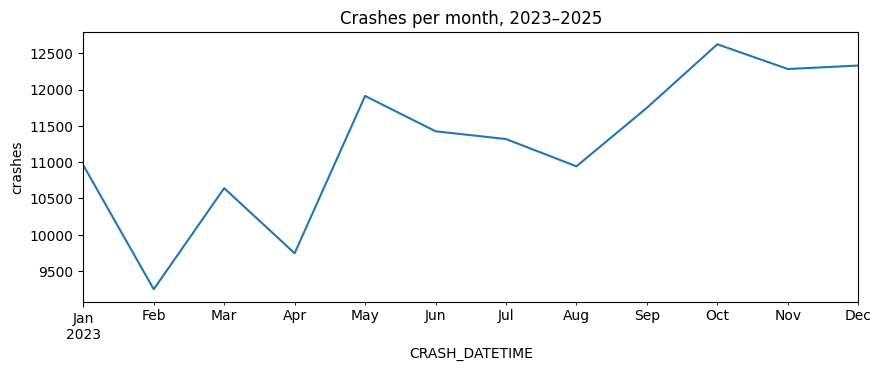

In [15]:
# Crashes per month, to spot gaps or a drop-off at the end of 2025
monthly = (
    pd.concat(crashes.values())
      .dropna(subset=["CRASH_DATETIME"])
      .set_index("CRASH_DATETIME")
      .resample("MS").size()
)
ax = monthly.plot(figsize=(10, 3.5), title="Crashes per month, 2023–2025")
ax.set_ylabel("crashes");

In [16]:
# A few example rows
pd.concat(crashes.values()).sample(5, random_state=0)

,CRASH_NUMB,CRASH_RPT_IDS,CRASH_DATETIME,YEAR,CITY_TOWN_NAME,X,Y,LAT,LON,RDWY,NEAR_INT_RDWY,DIST_DIRC_FROM_INT,RDWY_JNCT_TYPE_DESCR,CRASH_STATUS,IS_GEOCODED,GEOCODING_METHOD_NAME,CRASH_SEVERITY_DESCR,OBJECTID,source_service
13354,5226105,2300005157,NaT,2023,WESTWOOD,225618.511300,884968.172100,42.214747,-71.189730,WASHINGTON ST Rte S,NaN,NaN,Not at junction,Closed,Yes,At Address,Property damage only (none injured),4896702,MASSDOT_ODP_OPEN_2023v
49963,5265242,23-256-AC / 23-256-AC,2023-06-11 23:21:00,2023,DARTMOUTH,245734.684174,812924.606374,41.565208,-70.951714,SMITH NECK ROAD,NaN,NaN,Not at junction,Closed,Yes,Operator Designated,Non-fatal injury,4935586,MASSDOT_ODP_OPEN_2023v
22669,5235994,23-000395,2023-03-14 22:13:00,2023,TAUNTON,235882.665547,850697.817085,41.905803,-71.067526,Cape Rd Rte,NaN,NaN,Not at junction,Closed,Yes,At Address,Unknown,4906475,MASSDOT_ODP_OPEN_2023v
29180,5243265,23HAL-24-AC / 23HAL-24-AC,2023-04-13 08:06:00,2023,HALIFAX,253370.725679,858783.695618,41.977608,-70.856023,FRANKLIN ST Rte,NaN,NaN,Not at junction,Closed,Yes,At Address,Non-fatal injury,4913446,MASSDOT_ODP_OPEN_2023v
83470,5300033,23-31613-AC,2023-08-14 17:30:00,2023,MILFORD,197753.296976,876795.399664,42.141583,-71.527179,HIGH ST Rte,NaN,NaN,Not at junction,Closed,Yes,At Address,Property damage only (none injured),4969930,MASSDOT_ODP_OPEN_2023v


## 6. Conclusion

The crash data has everything we need for our label. Each year is about 131k–135k crashes,
and the ID, coordinates, road name, and junction type fields are there for all three years.
About 57% of crashes are "Not at junction," so that's roughly what we'll be working with for
the label. Around 96–97% of crashes are geocoded, so we only lose a small amount when matching
to roads.

A few things to keep in mind:
- 2025 has about 3% fewer crashes than the other years, probably because some reports
  haven't come in yet. 2024 and 2025 are both still marked "Open."
- We need to decide whether driveway and ramp crashes (about 6%) count as segment crashes.
- The download got cut off during 2024, so the data quality checks only ran on 2023. We need
  to re-run Section 4 to get 2024 and 2025.
